# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

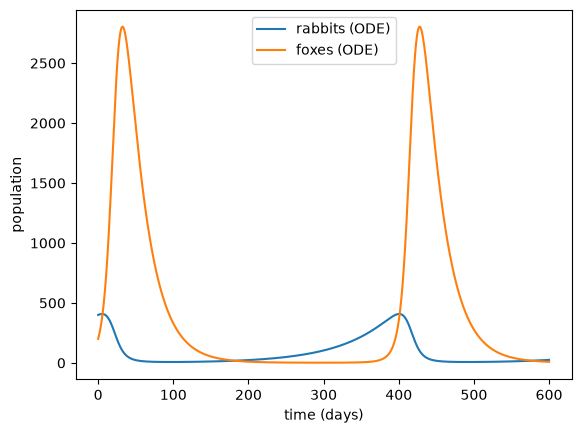

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:* The hand written rejuction-free KMC algoritham is written on paper and attached as Pdf doccument. At u = 0.5 and u' = 0.3, Foxes born is event happens and 1.464 minutes has passed.

**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

14578 events, 0.07 s, final rabbits: 1515, final foxes: 0


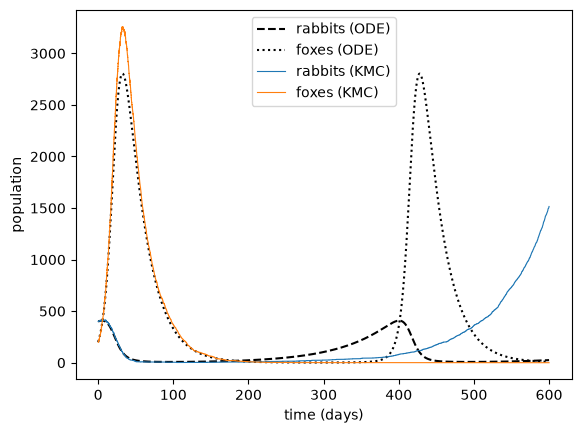

Seed 2: 22437 events, final rabbits: 105, final foxes: 8
Seed 3: 25009 events, final rabbits: 55, final foxes: 0
Seed 4: 24004 events, final rabbits: 128, final foxes: 8
Seed 5: 14242 events, final rabbits: 2126, final foxes: 0
Seed 6: 13841 events, final rabbits: 1271, final foxes: 0
Seed 7: 18357 events, final rabbits: 6419, final foxes: 0


In [29]:
def kmc(R0, F0, t_end, rng):
    R = R0
    F = F0
    t = 0.0
    times = [t]
    rabbits = [R]
    foxes = [F]

    while t < t_end:
        rate_rabbit_birth = k1*R
        rate_rabbit_eaten = k2*R*F
        rate_fox_birth = k3*R*F
        rate_fox_death = k4*F
    

        rate_total =rate_rabbit_birth + rate_rabbit_eaten + rate_fox_birth + rate_fox_death

        if rate_total ==0:
            break
        
        t += rng.exponential(1.0/ rate_total)
        if t >= t_end:
            break


        # Determine which event occurs
        u = rng.uniform(0, rate_total)
        if u < rate_rabbit_birth:
            R += 1
        elif u < rate_rabbit_birth + rate_rabbit_eaten:
            R -= 1
        elif u < rate_rabbit_birth + rate_rabbit_eaten + rate_fox_birth:
            F += 1
        else:
            F -= 1
        
        times.append(t)
        rabbits.append(R)
        foxes.append(F)
        

    return times, rabbits, foxes


def ode(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(ode, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 4000)
Y = ode.sol(t_ode)

rng = np.random.default_rng()
t0 = time.perf_counter()
times, rabbits, foxes = kmc(R0, F0, t_end, rng)
print(f"{len(times)} events, {time.perf_counter() - t0:.2f} s, final rabbits: {rabbits[-1]}, final foxes: {foxes[-1]}")

plt.plot(t_ode, Y[0], "k--", label="rabbits (ODE)")
plt.plot(t_ode, Y[1], "k:", label="foxes (ODE)")
plt.step(times, rabbits, where="post", color="tab:blue", lw=0.8, label="rabbits (KMC)")
plt.step(times, foxes, where="post", color="tab:orange", lw=0.8, label="foxes (KMC)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()


for seed in range(2,8):
    tm, rb, fx = kmc(R0, F0, t_end, np.random.default_rng(seed))
    print(f"Seed {seed}: {len(tm) -1} events, final rabbits: {rb[-1]}, final foxes: {fx[-1]}")


*Answer:*

There are 17305 events and it took 0.06s. Foxes first peak around day 32 both ODE and KMC shows foxes population abot 28000, but later ODE gives second peak at 420th day, KMC Foxes tragectory is almost flat line without any peaks which means that foxes are dead and resulting rabbits grows exponentially and reaching to 6000 at day 600. For few more seeds, the tragectory was same as 1st seed but there was an small count of foxes at end of day 600. 

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

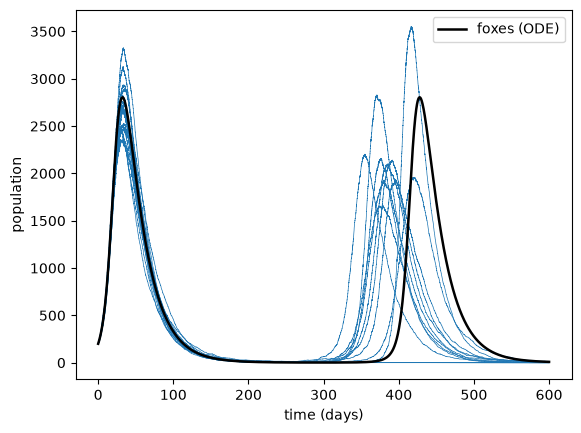

In [17]:
fig, ax = plt.subplots()
for seed in range(20):
    times, rabbits, foxes = kmc(R0, F0, t_end, np.random.default_rng(seed))
    ax.step(times, foxes, where="post", lw=0.5, color="tab:blue")

ax.plot(t_ode, Y[1], "k-", lw=1.8, label="foxes (ODE)")
ax.set_xlabel("time (days)")
ax.set_ylabel("population")
ax.legend()
plt.show()

*Answer:*

1) Initail at t=0 both trajectories are started at same population and even reached to similar maximum population at around day 32. However, at day 300 KCM there is an increase in Foxes population but in ODE population is only incresed on day 420. There is a foxes population raise from 280 to 450 in KMC. 
2) If popupation of foxes reaches zero, there will be an sharp raise in rabbits population and reaches to maximum at t_end(i.e.600). If Rabbits population reaches zero, there might not be extreme raise in foxes population because, rate of foxes birth is depends on rabbits too. 
3) Foxes population were 1.6 at t = 297 days, which is meaning less.  

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

fraction with a second peak: 29/100
times: mean 397.6, median 391.3, IQR 377.0-416.8
heights: mean 2201.4, median 2141.0, IQR 1976.0-2339.0


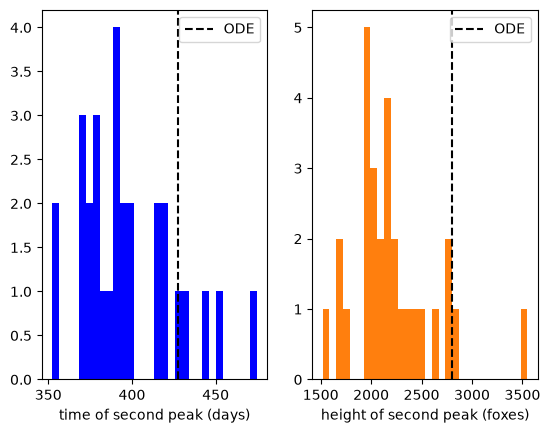

In [28]:
def second_peak(times, foxes, t_low=200.0, t_high=600, margin=5.0, min_height=100.0):
    times = np.array(times)
    foxes = np.array(foxes)
    f_low = foxes[np.searchsorted(times, t_low, side="right") - 1]
    m = (times >= t_low) & (times <= t_high)
    tw = np.concatenate(([times[0]], times[m], [t_high]))
    fw = np.concatenate(([f_low], foxes[m], [foxes[m][-1] if m.any() else f_low]))
    i = np.argmax(fw)
    t_peak = tw[i]
    h = fw[i]
    if h < min_height or t_peak <= t_low + margin or t_peak >= t_high - margin:
        return None
    return t_peak, h

results = []
for seed in range(100):
    tm, rb, fx = kmc(R0, F0, t_end, np.random.default_rng(seed))
    results.append(second_peak(tm, fx))

found = [r for r in results if r is not None]
T = np.array([r[0] for r in found])
H = np.array([r[1] for r in found])

print(f"fraction with a second peak: {len(found)}/100")

for name, x in [("times", T), ("heights", H)]:
    q1, q3 = np.percentile(x, [25, 75])
    print(f"{name}: mean {x.mean():.1f}, median {np.median(x):.1f}, IQR {q1:.1f}-{q3:.1f}")


fig, axs = plt.subplots(1, 2)
axs[0].hist(T, bins=30, color='blue')
axs[0].axvline(427.8, color="k", ls="--", label="ODE")
axs[0].set_xlabel("time of second peak (days)")
axs[0].legend()
axs[1].hist(H, bins=30, color="tab:orange")
axs[1].axvline(2804, color="k", ls="--", label="ODE")
axs[1].set_xlabel("height of second peak (foxes)")
axs[1].legend()


*Answer:*

1) The second peak in a KMC trajectory is on day 280 with the population of 2100. 

2) The second fraction is there at 29/200 fraction. 
3) The local maxima of foxes with atleat 100 population in the range of days 205 to 595 has mean and mediam time 397.6 days and 39.3 days and interquartile range is 40 days. Mean and mediam heights are 2201.4 and 2141.0 and IQR is 1976.0-2339.0.
4) The second peak KMC histograms differs from ODE both in days and heights. The trajectory where it doesn't called as second peak is not found in these range (200 to 600) because, the first trajectory starts on day 290  and last peak is at day 400. So, there are not peaks that stisfying the conditions mentioned. 

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

In [36]:
t_ini = time.perf_counter()

for seed in range(100):
    kmc(R0, F0, t_end, np.random.default_rng(seed))
dt = time.perf_counter() - t_ini
print(f"100 runs took {dt:.2f} s 3000 runs would take ~ {30*dt:.2f} s")

peaks = []
for seed in range(3000):
    tm, rb, fx = kmc(R0, F0, t_end, np.random.default_rng(seed))
    peaks.append(second_peak(tm, fx))
print(len(peaks))

for N in [100, 300, 1000, 3000]:
    found = [p for p in peaks[:N] if p is not None]
    t = np.array([p[0] for p in found])
    h = np.array([p[1] for p in found])
    n = len(found)
    print(f"N={N}: n={n}, "
         f"time {t.mean():.2f} +- {t.std(ddof=1)/np.sqrt(n):.2f}, "
         f"height{h.mean():.0f} +- {h.std(ddof=1)/np.sqrt(n):.0f}")


t = np.array([p[0] for p in peaks if p is not None])
h = np.array([p[1] for p in peaks if p is not None])
print("time 25/75:", np.percentile(t, [25, 75]))
print("height 25/75:", np.percentile(h, [25, 75]))


100 runs took 7.45 s 3000 runs would take ~ 223.46 s
3000
N=100: n=29, time 397.56 +- 5.41, height2201 +- 78
N=300: n=94, time 394.59 +- 2.88, height2247 +- 55
N=1000: n=320, time 399.10 +- 1.72, height2315 +- 31
N=3000: n=976, time 400.17 +- 1.01, height2370 +- 20
time 25/75: [378.26191189 417.52520858]
height 25/75: [1934.   2703.25]


*Answer:*

The mean time and height at N=100 is same as above question but as the number of runs increases mean time and height is being incresed gradually. As number of trajectories increses the stand error is being decresed which means that the solution is being converged to absolute value with minimum tollerance. The IQR range is similar to problem 3. The IQR measures the spread of the distribution (how much one trajectory’s peak varies from another), not the uncertainty of an estimate. More runs don’t make the distribution narrower. 

## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

*Answer:*

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*

I am planning to do enzymatic reaction in bioreactor. The kinetic reaction is very complex because there are three different molecules changes with respect to time and process parameters. The possible events are enzyme reacting with the reactents(r1), rate of reaction (would be easily 3 stages) so possible events are r2, r3, r4. These model is higer order defferential equation. It requires large number of smaller steps to converge the solution. 

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.